# Example of the aitlas toolbox in the context of semantic segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox. The OSM dataset contains 3 possible classification schemas (land_use, water_and_roads and builings).

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import OpenSentinelMapDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor
import matplotlib.pyplot as plt

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir" : "./data/OpenSentinelMap/",
    "classification" : "all" # to visualize the 3 classification schemas
}
dataset = OpenSentinelMapDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 354156


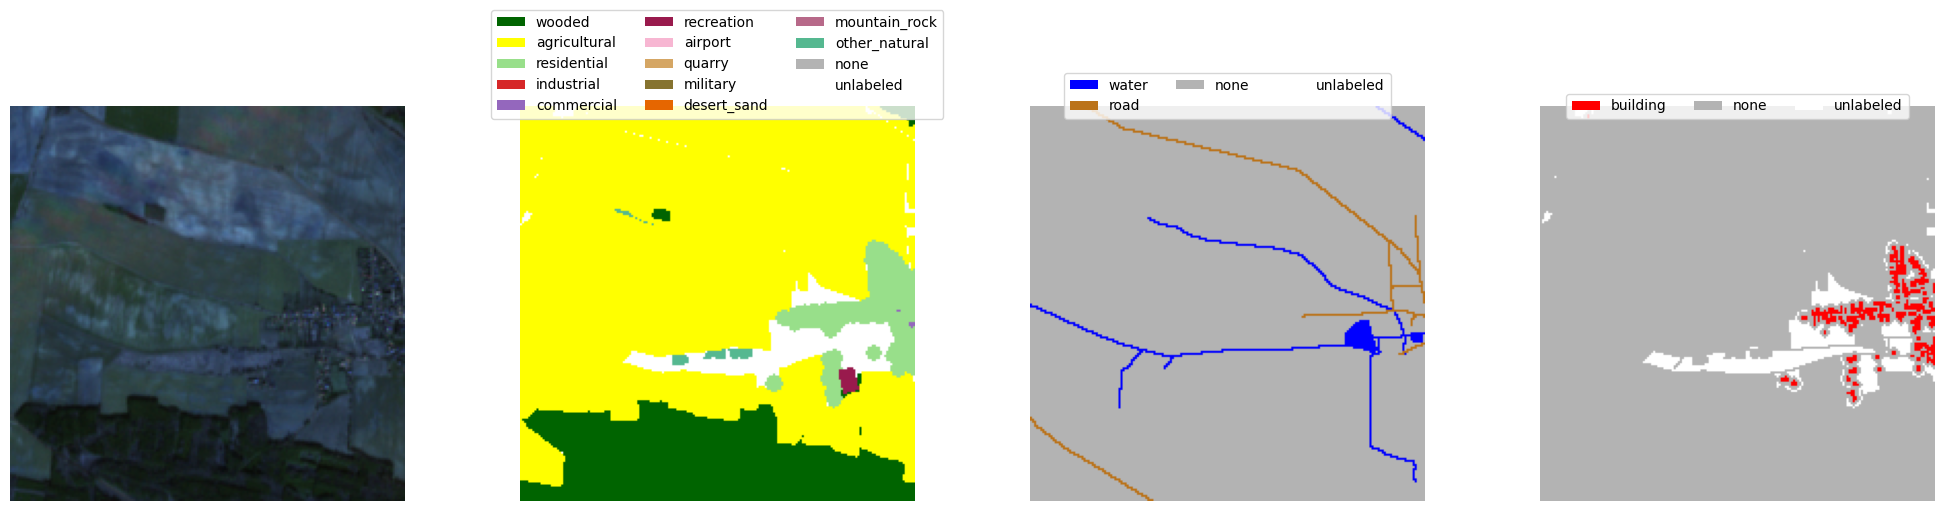

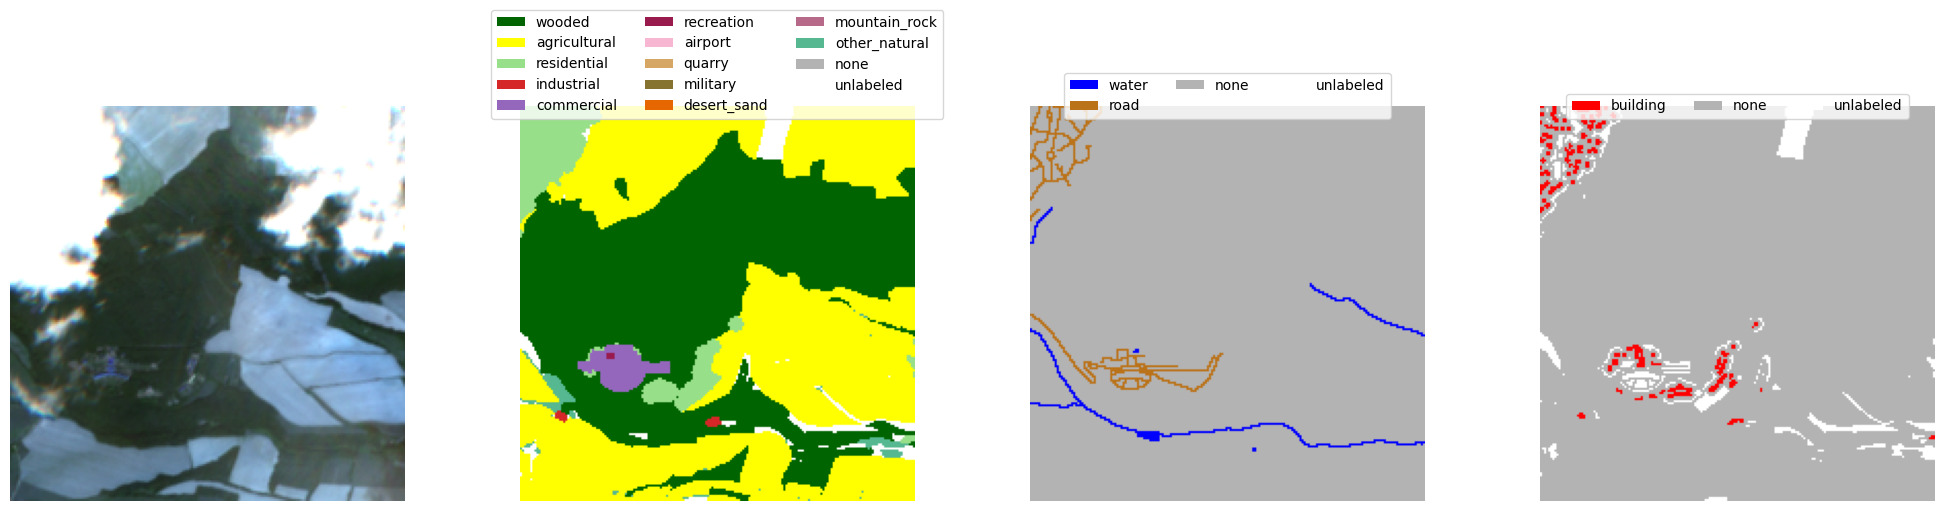

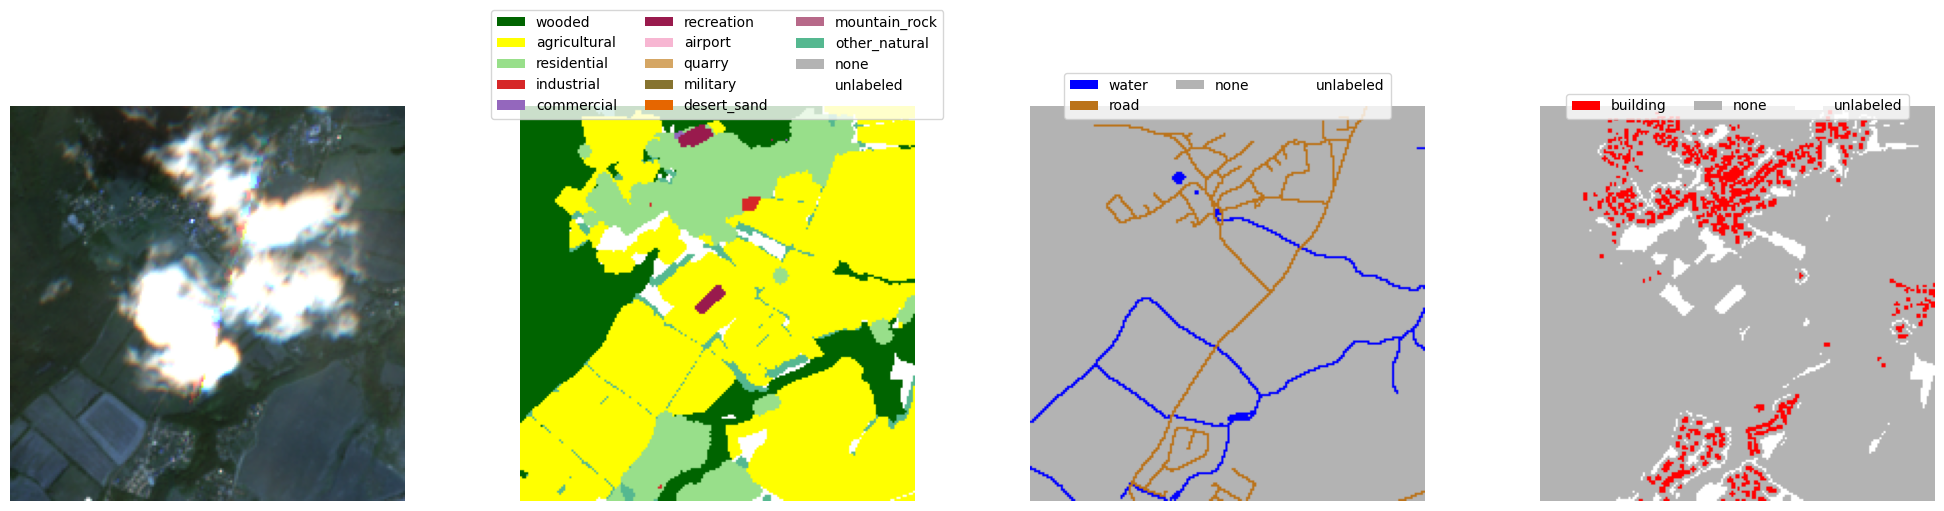

In [239]:
dataset.show_image(1000);
dataset.show_image(5000);
dataset.show_image(2500);

## Analyse the land use classification schema

In [ ]:
dataset_config = {
    "data_dir" : "./data/OpenSentinelMap/",
    "classification" : "land_use"
}
dataset = OpenSentinelMapDataset(dataset_config)

In [216]:
dataset.data_distribution_table()

,Number of pixels
wooded,1.199300e+09
agricultural,1.038762e+09
residential,5.003910e+08
industrial,8.646626e+07
commercial,3.476549e+07
recreation,2.968221e+07
airport,2.114772e+07
quarry,2.837324e+07
military,2.465643e+07
desert_sand,1.341639e+07


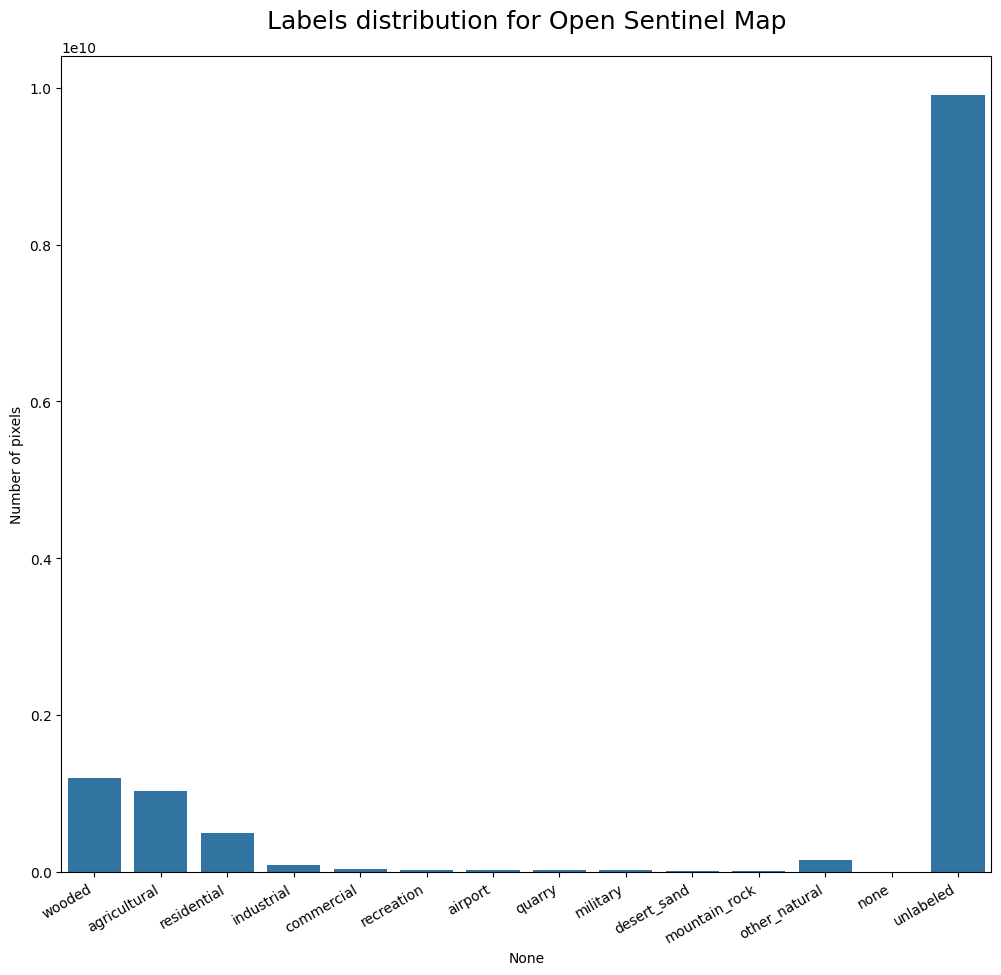

In [217]:
dataset.data_distribution_barchart();

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 64,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/OpenSentinelMap/",
    "classification" : "land_use",
    "mode": "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = OpenSentinelMapDataset(train_dataset_config)

len(train_dataset)

283325

## Create the model ##

In [ ]:
epochs = 10
model_directory = "./data/experiments/OSM"
model_config = {
    "num_classes": 14, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [13]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-09-10 07:57:28,705 INFO Starting training.
training: 100%|██████████| 4427/4427 [1:26:06<00:00,  1.17s/it]
2025-09-10 09:23:34,823 INFO epoch: 1, time: 5166, loss:  0.23378
testing on train set: 100%|██████████| 4427/4427 [34:37<00:00,  2.13it/s]
2025-09-10 09:58:14,865 INFO IOU:0.6926422024278107, IOU mean:0.12927790603052955, IOU per Class:[0.44677374 0.29606019 0.25830133 0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.80875542]
training: 100%|██████████| 4427/4427 [1:29:48<00:00,  1.22s/it]
2025-09-10 11:28:03,664 INFO epoch: 2, time: 5389, loss:  0.17712
testing on train set: 100%|██████████| 4427/4427 [20:49<00:00,  3.54it/s]
2025-09-10 11:48:53,183 INFO IOU:0.7108910021740016, IOU mean:0.13905887091180574, IOU per Class:[0.45444416 0.34023986 0.33491259 0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.81722758]
training: 100%|██████████| 4427/4427 [50:08<00:00,  1.47it/s]
2025

0.1501178647760132

## Evaluate the model ##

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir" : "./data/OpenSentinelMap/",
    "classification" : "land_use",
    "mode": "val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose"],
    "target_transforms": ["aitlas.transforms.Transpose"]
}

test_dataset = OpenSentinelMapDataset(test_dataset_config)
len(test_dataset)

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/OSM/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-09-11 06:32:35,128 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/OSM/checkpoint.pth.tar
2025-09-11 06:32:35,628 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/OSM/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 8854/8854 [02:55<00:00, 50.56it/s]


[{'IOU': 0.6081956634081769,
  'IOU mean': 0.10841150948929197,
  'IOU per Class': array([0.33354968, 0.14209658, 0.30021818, 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.74189669])}]

## Predictions

2025-09-11 06:38:15,636 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/OSM/checkpoint.pth.tar
2025-09-11 06:38:16,685 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/OSM/checkpoint.pth.tar at epoch 11


35415


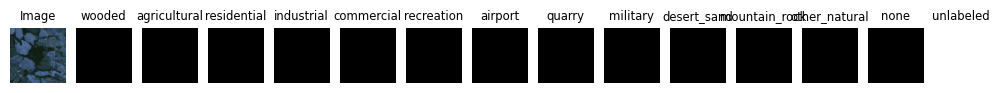

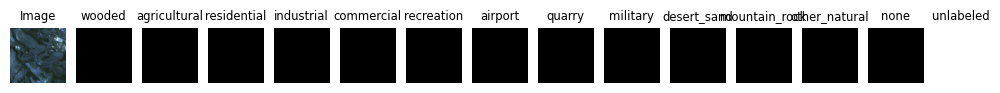

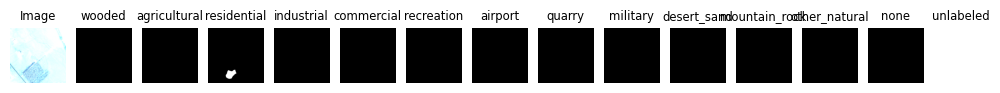

In [ ]:
model_path = "./data/experiments/OSM/checkpoint.pth.tar"
labels_land_use = [
        "wooded",
        "agricultural",
        "residential",
        "industrial",
        "commercial",
        "recreation",
        "airport",
        "quarry",
        "military",
        "desert_sand",
        "mountain_rock",
        "other_natural",
        "none",
        "unlabeled"
    ]
transform = ResizeToTensor()
model.load_model(model_path)

plt.rcParams.update({'font.size': 7})

test_dataset_config = {
    "data_dir" : "./data/OpenSentinelMap/",
    "classification" : "land_use",
    "mode": "test",
}

test_dataset = OpenSentinelMapDataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_masks(image, labels_land_use, transform)

image = test_dataset[10][0]
fig = model.predict_masks(image, labels_land_use, transform)

image = test_dataset[3000][0]
fig = model.predict_masks(image, labels_land_use, transform)